In [27]:
# --- imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from imblearn.over_sampling import SMOTE
from sklearn.utils import Bunch


In [35]:
FEATS = [
    "fix_efficiency","fix_aoi_ratio","gaze_dispersion_total",
    "pupil_mean","pupil_var","saccade_mean_mag","saccade_dir_var",
    "blink_rate","valid_gaze_ratio",
]

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.utils import resample
import seaborn as sns, matplotlib.pyplot as plt
import numpy as np, pandas as pd

def _impute_drop_correlate_scale(X: pd.DataFrame, corr_cut=0.90, var_min=1e-6):
    """Impute (median) → drop near-constant → drop |r|>corr_cut → scale. Returns (X_scaled, kept_cols)."""
    imp = SimpleImputer(strategy="median")
    X = pd.DataFrame(imp.fit_transform(X), columns=X.columns, index=X.index)

    var = X.var()
    keep = var[var > var_min].index.tolist()
    X = X[keep]

    corr = X.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    drop_cols = [c for c in upper.columns if (upper[c] > corr_cut).any()]
    kept_cols = [c for c in X.columns if c not in drop_cols]
    if drop_cols:
        print("Dropping for high correlation:", drop_cols)
    X = X[kept_cols]

    X_scaled = StandardScaler().fit_transform(X)
    return X_scaled, kept_cols

def kmeans_with_subsampling(df: pd.DataFrame, title: str = "Dataset", corr_cut=0.90):
    d = df.copy()
    d["label"] = d["label"].astype(str).str.upper().str.strip()
    d = d[d["label"].isin(["ON","OFF"])].copy()

    # ---------- (A) PCA on full (unbalanced) data with clean-up ----------
    X_full_raw = d[FEATS].copy()
    X_full, kept_full = _impute_drop_correlate_scale(X_full_raw, corr_cut=corr_cut)
    print(f"[{title}] PCA uses features:", kept_full)

    pca_full = PCA(n_components=2, random_state=0)
    PCs_full = pca_full.fit_transform(X_full)
    d["PC1_full"], d["PC2_full"] = PCs_full[:,0], PCs_full[:,1]

    plt.figure(figsize=(7,5))
    sns.scatterplot(data=d, x="PC1_full", y="PC2_full", hue="label", alpha=0.6)
    plt.title(f"PCA (unbalanced) — {title}  |  EVR: {pca_full.explained_variance_ratio_[0]:.2f}, {pca_full.explained_variance_ratio_[1]:.2f}")
    plt.axhline(0, ls="--", lw=0.5); plt.axvline(0, ls="--", lw=0.5)
    plt.tight_layout(); plt.show()

    # ---------- (B) Undersample majority → KMeans on balanced set ----------
    off = d[d["label"]=="OFF"]
    on  = d[d["label"]=="ON"]
    if len(off)==0 or len(on)==0:
        print(f"[{title}] Not enough ON/OFF to balance.")
        return

    minority = off if len(off) <= len(on) else on
    majority = on  if len(on)  >  len(off) else off
    majority_down = resample(majority, replace=False, n_samples=len(minority), random_state=0)

    dbal = pd.concat([minority, majority_down], axis=0).sample(frac=1, random_state=0).reset_index(drop=True)
    print(f"[{title}] Balanced counts:\n", dbal["label"].value_counts())

    Xb_raw = dbal[FEATS].copy()
    Xb, kept_bal = _impute_drop_correlate_scale(Xb_raw, corr_cut=corr_cut)
    if kept_bal != kept_full:
        print(f"[{title}] (info) kept features differ after balancing.")

    km2 = KMeans(n_clusters=2, n_init="auto", random_state=0)
    k_lab = km2.fit_predict(Xb)

    # majority-map clusters → ON/OFF
    mapping = (pd.DataFrame({"c":k_lab,"t":dbal["label"]})
               .groupby("c")["t"].agg(lambda s: s.value_counts().idxmax())).to_dict()
    mapped = np.vectorize(mapping.get)(k_lab)
    acc = (mapped == dbal["label"].values).mean()
    sil = silhouette_score(Xb, k_lab) if len(np.unique(k_lab))>1 else np.nan
    print(f"[{title}] KMeans k=2 (undersampled) → silhouette={sil:.3f}, acc vs ON/OFF={acc:.3f}, map={mapping}")
    print(pd.crosstab(pd.Series(k_lab, name="cluster_k"), dbal["label"], normalize="index"))

    # visualize clusters in balanced PCA space
    pca_b = PCA(n_components=2, random_state=0)
    PCs_b = pca_b.fit_transform(Xb)
    dbal["PC1_b"], dbal["PC2_b"], dbal["cluster_k"] = PCs_b[:,0], PCs_b[:,1], k_lab

    plt.figure(figsize=(7,5))
    sns.scatterplot(data=dbal, x="PC1_b", y="PC2_b", hue="cluster_k", alpha=0.7)
    plt.title(f"KMeans (k=2) on undersampled features — visualized in PCA space\n{title}")
    plt.axhline(0, ls="--", lw=0.5); plt.axvline(0, ls="--", lw=0.5)
    plt.tight_layout(); plt.show()

In [32]:
windows_1 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task1.csv")
windows_2 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task2.csv")
windows_3 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task3.csv")

[Task 1.x] PCA uses features: ['fix_efficiency', 'gaze_dispersion_total', 'pupil_mean', 'pupil_var', 'saccade_mean_mag', 'saccade_dir_var', 'blink_rate', 'valid_gaze_ratio']


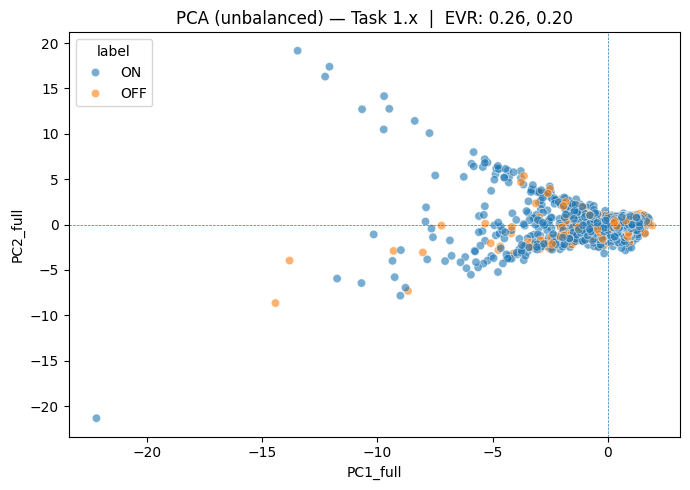

[Task 1.x] Balanced counts:
 label
ON     1198
OFF    1198
Name: count, dtype: int64
[Task 1.x] KMeans k=2 (undersampled) → silhouette=0.407, acc vs ON/OFF=0.502, map={0: 'ON', 1: 'OFF'}
label           OFF        ON
cluster_k                    
0          0.498912  0.501088
1          0.503584  0.496416


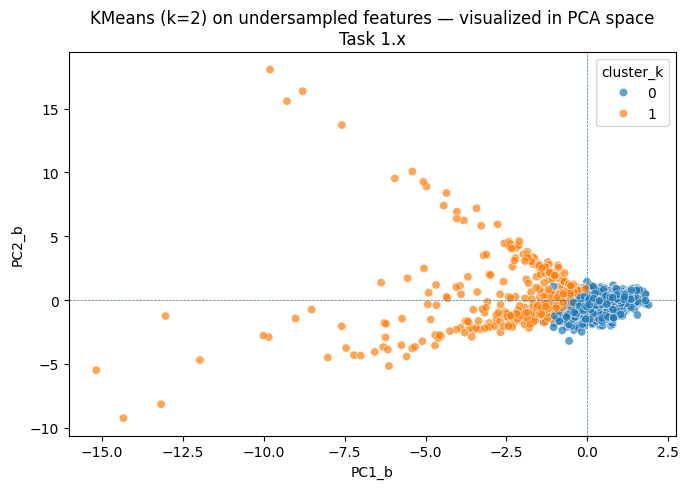

[Task 2.x] PCA uses features: ['fix_efficiency', 'fix_aoi_ratio', 'gaze_dispersion_total', 'pupil_mean', 'pupil_var', 'saccade_mean_mag', 'saccade_dir_var', 'blink_rate', 'valid_gaze_ratio']


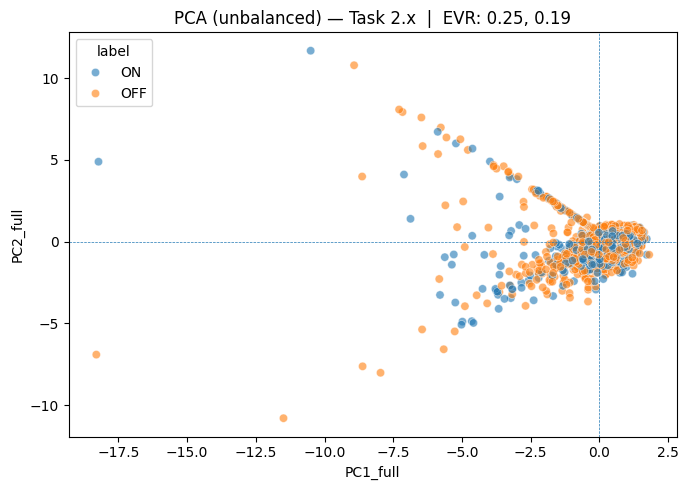

[Task 2.x] Balanced counts:
 label
ON     745
OFF    745
Name: count, dtype: int64
[Task 2.x] KMeans k=2 (undersampled) → silhouette=0.666, acc vs ON/OFF=0.507, map={0: 'OFF', 1: 'ON'}
label           OFF        ON
cluster_k                    
0          0.503536  0.496464
1          0.434211  0.565789


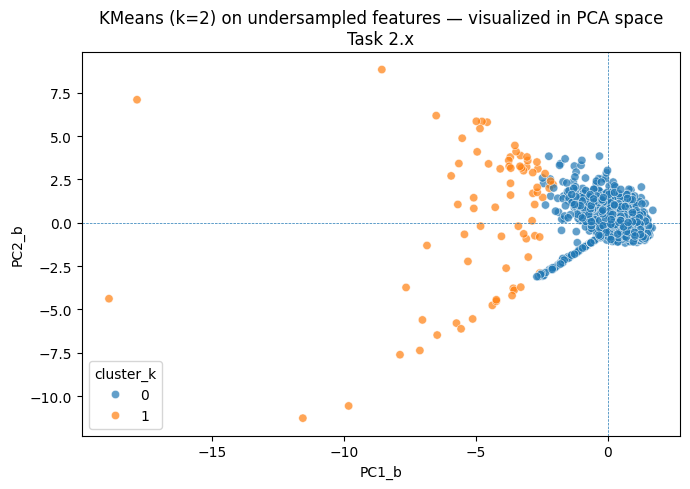

[Task 3.x] PCA uses features: ['fix_efficiency', 'gaze_dispersion_total', 'pupil_mean', 'pupil_var', 'saccade_mean_mag', 'saccade_dir_var', 'blink_rate', 'valid_gaze_ratio']


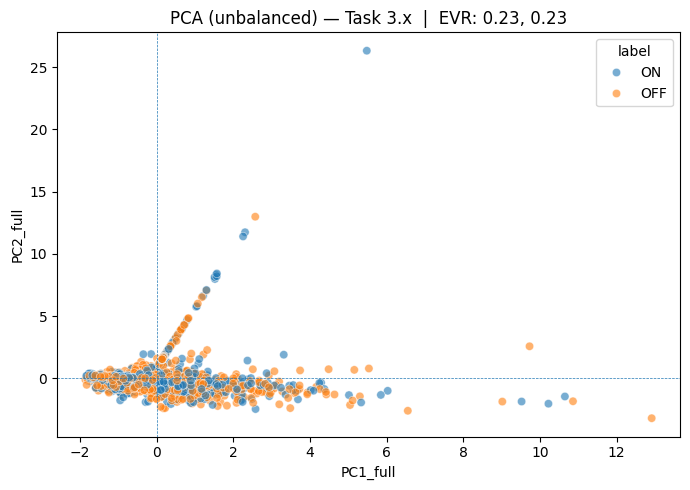

[Task 3.x] Balanced counts:
 label
ON     745
OFF    745
Name: count, dtype: int64
[Task 3.x] KMeans k=2 (undersampled) → silhouette=0.446, acc vs ON/OFF=0.511, map={0: 'ON', 1: 'OFF'}
label           OFF        ON
cluster_k                    
0          0.493808  0.506192
1          0.540404  0.459596


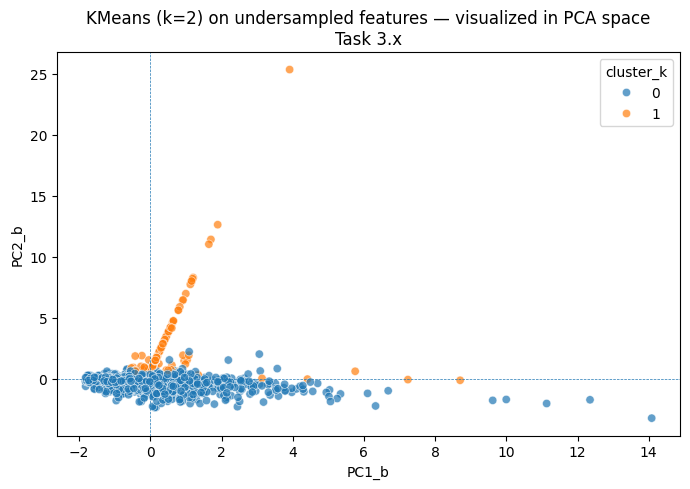

In [37]:
kmeans_with_subsampling(win1, title="Task 1.x", corr_cut=0.90)
kmeans_with_subsampling(win2, title="Task 2.x", corr_cut=0.90)
kmeans_with_subsampling(win3, title="Task 3.x", corr_cut=0.90)

In [38]:
def pca_loadings_per_task(task_dfs: dict, feats=FEATS):
    """
    Compute PCA loadings (feature contributions) separately for each task dataset.
    
    task_dfs: dict { "Task 1.x": df1, "Task 2.x": df2, "Task 3.x": df3 }
    feats: list of feature columns
    """
    for name, df in task_dfs.items():
        print(f"\n=== {name} ===")

        # --- Features only ---
        X = df[feats].copy()
        X = X.fillna(X.median(numeric_only=True))  # impute
        X = StandardScaler().fit_transform(X)

        # --- PCA ---
        pca = PCA(n_components=2, random_state=0)
        PCs = pca.fit_transform(X)

        print(f"[{name}] Explained variance ratio: {pca.explained_variance_ratio_}")

        # --- Loadings (features × components) ---
        loadings = pd.DataFrame(
            pca.components_.T,
            index=feats,
            columns=[f"PC{i+1}" for i in range(pca.n_components_)]
        )

        # --- Show top features for PC1 and PC2 ---
        for pc in ["PC1", "PC2"]:
            print(f"\nTop features driving {pc} ({name}):")
            print(loadings[pc].abs().sort_values(ascending=False).head(8))

            # Plot bar chart
            plt.figure(figsize=(7,4))
            sns.barplot(
                x=loadings[pc].abs().sort_values(ascending=False).head(8),
                y=loadings[pc].abs().sort_values(ascending=False).head(8).index,
                palette="viridis"
            )
            plt.title(f"{name} — Top 8 features for {pc}")
            plt.xlabel("Absolute loading (importance)")
            plt.tight_layout()
            plt.show()


=== Task 1.x ===
[Task 1.x] Explained variance ratio: [0.25912918 0.19714429]

Top features driving PC1 (Task 1.x):
valid_gaze_ratio         0.496820
pupil_mean               0.416706
saccade_dir_var          0.370835
saccade_mean_mag         0.361440
pupil_var                0.319030
gaze_dispersion_total    0.304506
fix_efficiency           0.297857
blink_rate               0.167769
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


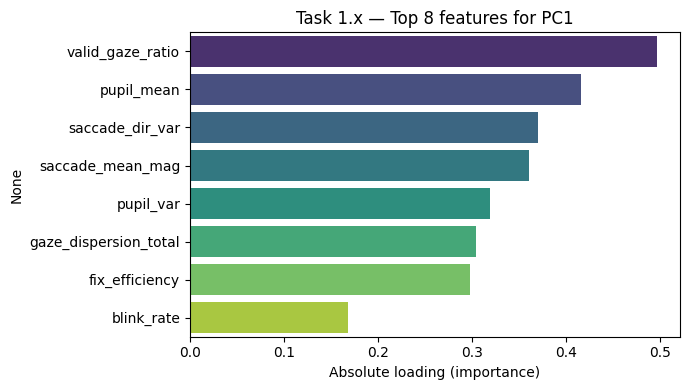


Top features driving PC2 (Task 1.x):
pupil_var                0.494625
pupil_mean               0.458808
saccade_dir_var          0.364052
blink_rate               0.362483
fix_efficiency           0.359748
gaze_dispersion_total    0.319629
saccade_mean_mag         0.221259
valid_gaze_ratio         0.019436
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


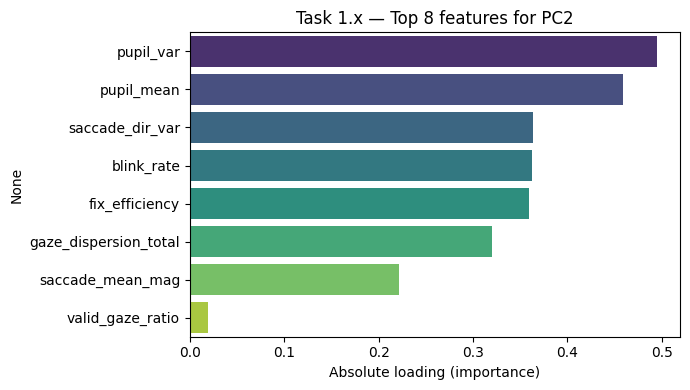


=== Task 2.x ===
[Task 2.x] Explained variance ratio: [0.24639678 0.19447167]

Top features driving PC1 (Task 2.x):
valid_gaze_ratio         0.458575
pupil_var                0.392788
saccade_mean_mag         0.391823
pupil_mean               0.375443
saccade_dir_var          0.367665
fix_efficiency           0.305279
gaze_dispersion_total    0.287680
blink_rate               0.172154
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


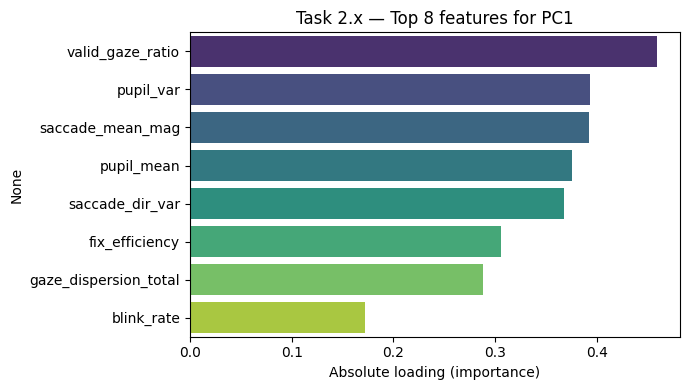


Top features driving PC2 (Task 2.x):
pupil_mean               0.444290
fix_efficiency           0.435525
blink_rate               0.411944
pupil_var                0.384740
gaze_dispersion_total    0.369560
saccade_dir_var          0.361924
saccade_mean_mag         0.139391
valid_gaze_ratio         0.081998
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


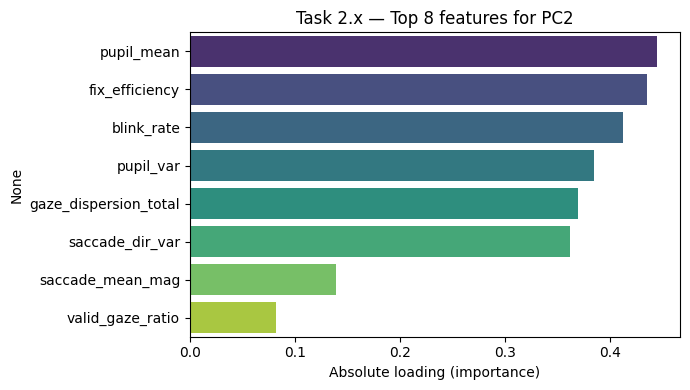


=== Task 3.x ===
[Task 3.x] Explained variance ratio: [0.23279625 0.2286071 ]

Top features driving PC1 (Task 3.x):
fix_efficiency           0.524983
gaze_dispersion_total    0.455578
saccade_dir_var          0.453706
valid_gaze_ratio         0.445015
saccade_mean_mag         0.293975
pupil_mean               0.120053
pupil_var                0.109281
blink_rate               0.013336
Name: PC1, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


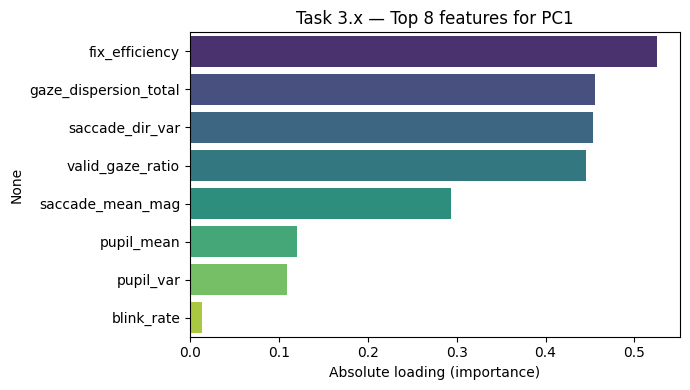


Top features driving PC2 (Task 3.x):
pupil_mean               0.578434
pupil_var                0.500012
blink_rate               0.462564
valid_gaze_ratio         0.305629
saccade_dir_var          0.256723
fix_efficiency           0.175383
gaze_dispersion_total    0.106113
saccade_mean_mag         0.010090
Name: PC2, dtype: float64


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_3119/3671864196.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


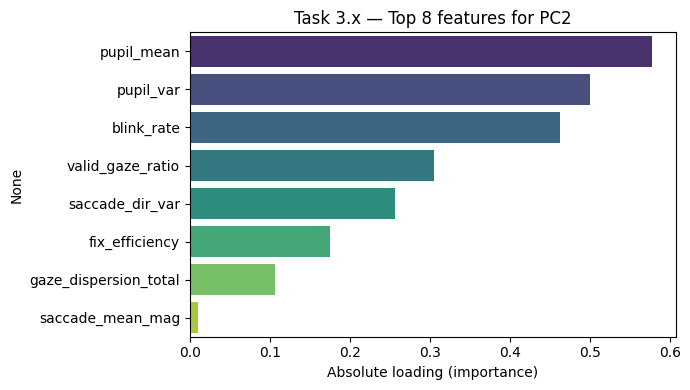

In [39]:
task_dfs = {
    "Task 1.x": win1,
    "Task 2.x": win2,
    "Task 3.x": win3,
}

pca_loadings_per_task(task_dfs)